# Exploración de datos – Riesgo de prórroga en contratos SECOP II

**Pregunta de negocio:** al firmar un contrato público, ¿qué tan probable es que requiera una prórroga?

Datos: `data/processed/contratos_modelo.parquet`, generado por `dvc repro` (Contratos + Procesos + Proveedores,
firmados 2023–2024 y ya terminados). Objetivo: `prorrogado = 1` si `dias_adicionados > 0`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.float_format", "{:,.3f}".format)

df = pd.read_parquet(ROOT / "data/processed/contratos_modelo.parquet")
resumen = json.load(open(ROOT / "data/processed/resumen.json", encoding="utf-8"))
FUGA = resumen["columnas_fuga"]
print(f"{len(df):,} contratos x {df.shape[1]} columnas")
resumen

1,697,301 contratos x 86 columnas


{'contratos_descargados': 1717440,
 'contratos_finales': 1697301,
 'tasa_prorroga': 0.1221,
 'cruce_procesos': 0.9961,
 'cruce_proveedores': 0.9807,
 'columnas_fuga': ['valor_facturado',
  'valor_pagado',
  'valor_pendiente_de_ejecucion',
  'estado_contrato',
  'liquidaci_n',
  'ultima_actualizacion',
  'dias_adicionados',
  'fecha_de_fin_del_contrato',
  'duracion_real_dias',
  'valor_del_contrato',
  'log_valor',
  'ratio_valor_precio_base']}

In [2]:
def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def tasa_por(col, min_n=500, top=15):
    t = (df.groupby(col, observed=True)["prorrogado"].agg(n="size", tasa="mean")
           .query("n >= @min_n").sort_values("tasa", ascending=False).head(top))
    return t

TASA_GLOBAL = df["prorrogado"].mean()

## 1. Calidad de los datos

In [3]:
nulos = (df.isna().mean().sort_values(ascending=False) * 100).round(1)
calidad = pd.DataFrame({"% nulos": nulos, "valores únicos": df.nunique()[nulos.index]})
calidad.head(25)

,% nulos,valores únicos
proc_fecha_adjudicacion,91.500,813
proc_fecha_de_recepcion_de,91.100,743
ultima_actualizacion,30.600,1322
prov_espyme,1.900,2
prov_es_grupo,1.900,1
prov_esta_activa,1.900,2
prov_codigo,1.900,699766
prov_codigo_categoria_principal,1.900,231
prov_fecha_creacion,1.900,696055
prov_municipio,1.900,1059


In [4]:
# Valores centinela "No Definido" / "No Aplica" que no aparecen como nulos
cat = df.select_dtypes("object")
centinelas = cat.apply(lambda s: s.isin(["No Definido", "No definido", "No Aplica", "No aplica", "No Provisto"]).mean() * 100)
centinelas[centinelas > 5].sort_values(ascending=False).round(1)

C:\Users\Camilo\AppData\Local\Temp\ipykernel_12496\2077909495.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat = df.select_dtypes("object")


proc_subtipo_de_contrato          99.600
prov_codigo_categoria_principal   96.600
prov_tama_o_entidad               90.100
prov_municipio                    34.000
prov_departamento                 30.200
ciudad                            19.500
dtype: float64

In [5]:
print("Precio base del proceso (COP):")
print(df["proc_precio_base"].describe(percentiles=[.01, .25, .5, .75, .99]).apply(lambda v: f"{v:,.0f}"))
print("\nDuración pactada (días):")
print(df["duracion_pactada_dias"].describe(percentiles=[.01, .5, .99]).round(1))

Precio base del proceso (COP):
count            1,690,605
mean           227,441,108
std          8,330,526,837
min        -34,693,400,216
1%               1,590,000
25%              9,000,000
50%             18,006,972
75%             41,428,660
99%          2,949,717,600
max      3,406,725,000,000
Name: proc_precio_base, dtype: str

Duración pactada (días):
count     1,697,073.000
mean            590.700
std         252,679.200
min               0.000
1%                7.000
50%             120.000
99%             390.000
max     285,410,138.000
Name: duracion_pactada_dias, dtype: float64


## 2. Variable objetivo

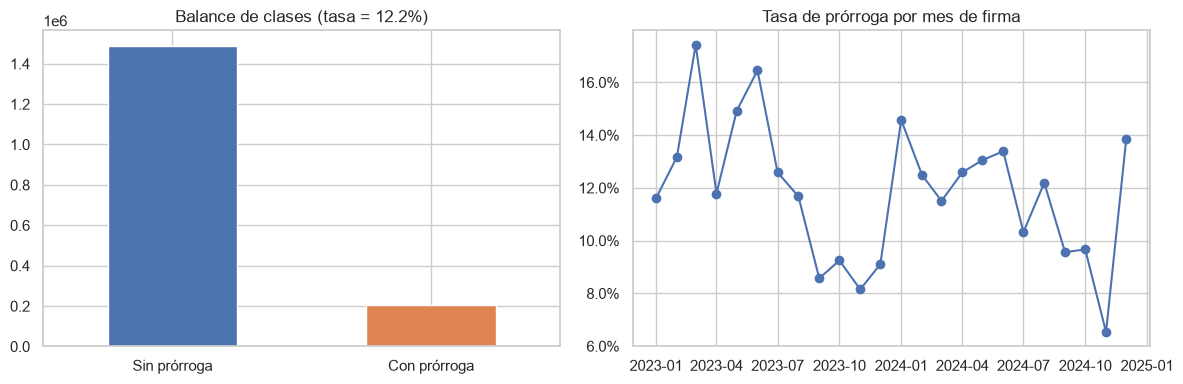

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["prorrogado"].map({0: "Sin prórroga", 1: "Con prórroga"}).value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title(f"Balance de clases (tasa = {TASA_GLOBAL:.1%})"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=0)
m = df.groupby(df["fecha_de_firma"].dt.to_period("M"))["prorrogado"].agg(["mean", "size"])
axes[1].plot(m.index.to_timestamp(), m["mean"], marker="o")
axes[1].set_title("Tasa de prórroga por mes de firma"); axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
guardar("01_objetivo")

count   207,268.000
mean         53.000
std       1,461.000
min           1.000
25%          24.000
50%          35.000
75%          61.000
90%          92.000
max     664,742.000
Name: dias_adicionados, dtype: float64


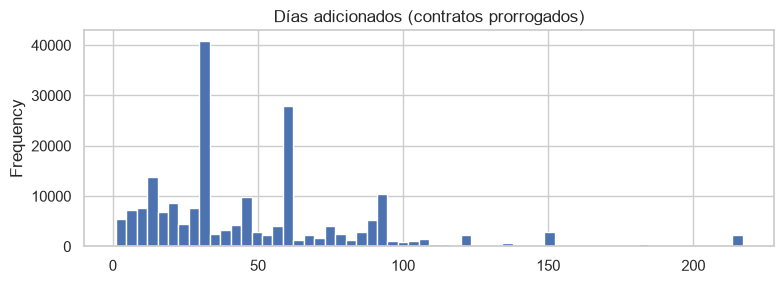

In [7]:
dias = df.loc[df["prorrogado"] == 1, "dias_adicionados"]
print(dias.describe(percentiles=[.25, .5, .75, .9]).round(0))
dias.clip(upper=dias.quantile(.99)).plot.hist(bins=60, figsize=(8, 3), title="Días adicionados (contratos prorrogados)")
guardar("02_dias_adicionados")

## 3. ¿Qué características del contrato se asocian a la prórroga?

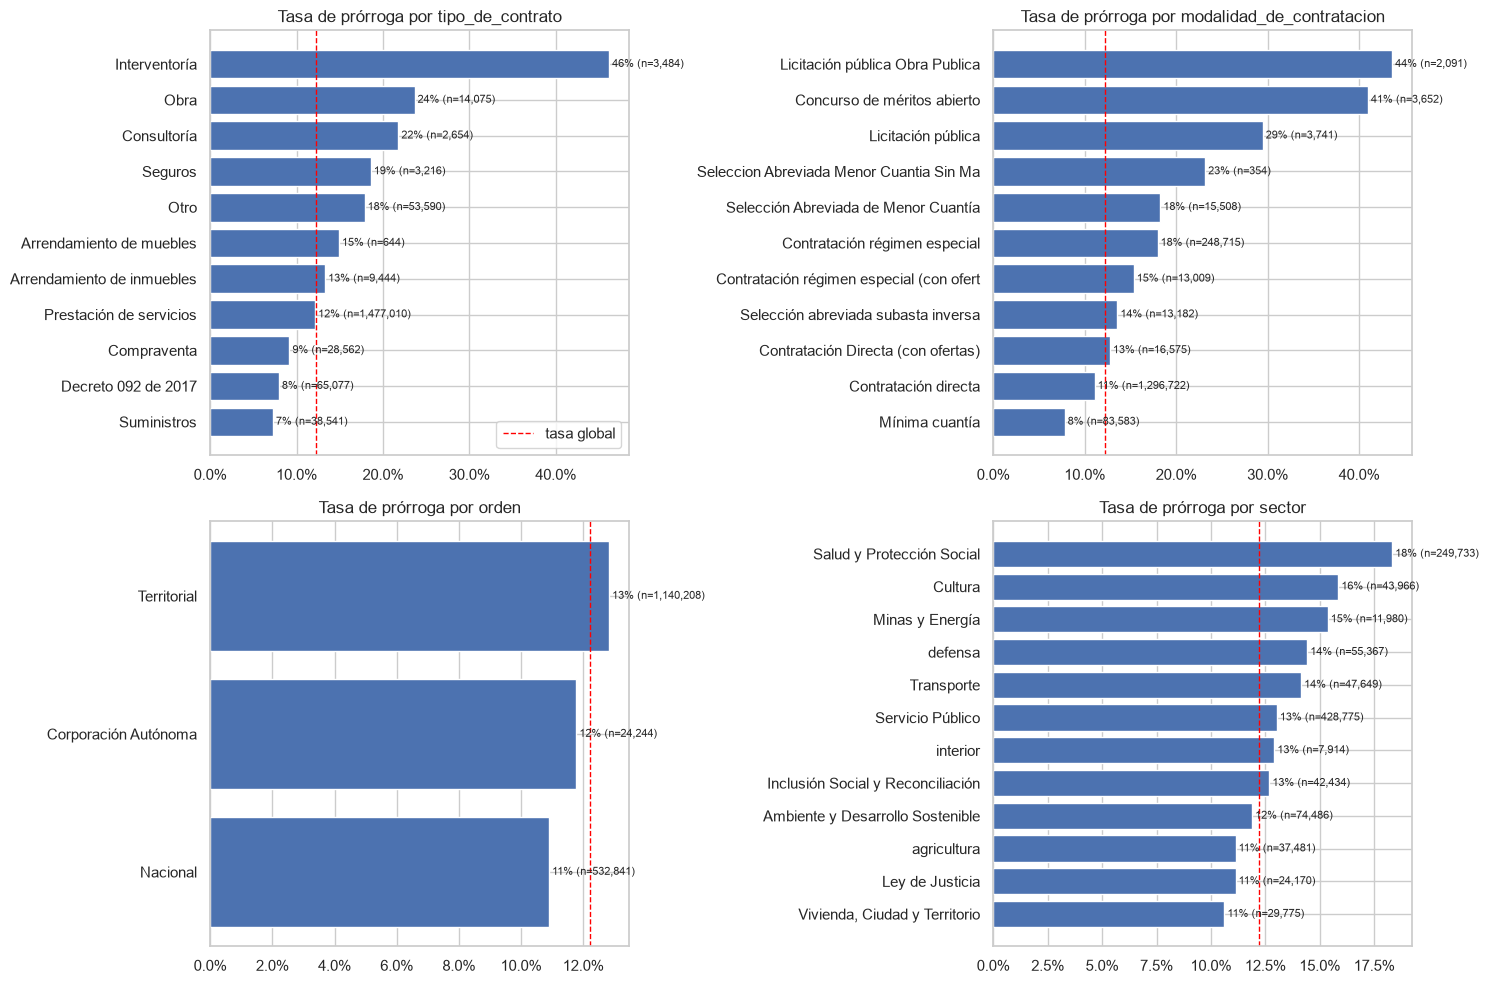

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col, n in zip(axes.flat,
                      ["tipo_de_contrato", "modalidad_de_contratacion", "orden", "sector"],
                      [300, 300, 300, 1000]):
    t = tasa_por(col, min_n=n, top=12).sort_values("tasa")
    ax.barh(t.index.astype(str).str[:40], t["tasa"], color="#4C72B0")
    ax.axvline(TASA_GLOBAL, color="red", ls="--", lw=1, label="tasa global")
    for i, (tasa, nn) in enumerate(zip(t["tasa"], t["n"])):
        ax.text(tasa, i, f" {tasa:.0%} (n={nn:,})", va="center", fontsize=8)
    ax.set_title(f"Tasa de prórroga por {col}"); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0, 0].legend()
guardar("03_tasa_categorias")

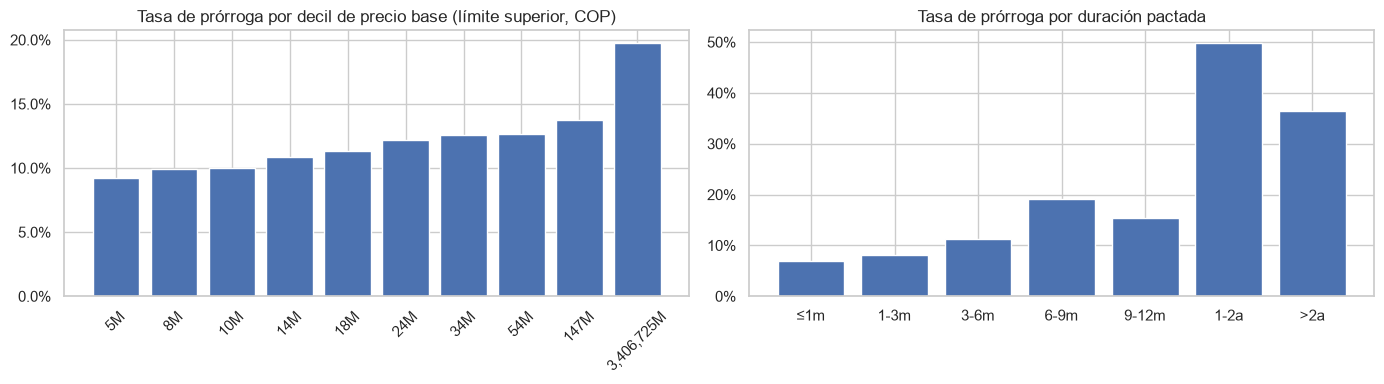

,mean,size
rango_duracion,,
≤1m,0.070,170203
1-3m,0.081,428658
3-6m,0.112,599030
6-9m,0.192,237325
9-12m,0.154,238851
1-2a,0.498,19313
>2a,0.365,3613


In [9]:
# Precio base (fijado antes de la firma; ver sección 6) y duración pactada
df["decil_valor"] = pd.qcut(df["proc_precio_base"].where(df["proc_precio_base"] > 0), 10, duplicates="drop")
df["rango_duracion"] = pd.cut(df["duracion_pactada_dias"], [0, 30, 90, 180, 270, 365, 730, np.inf],
                              labels=["≤1m", "1-3m", "3-6m", "6-9m", "9-12m", "1-2a", ">2a"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
v = df.groupby("decil_valor", observed=True)["prorrogado"].mean()
axes[0].bar(range(len(v)), v.values); axes[0].set_xticks(range(len(v)))
axes[0].set_xticklabels([f"{i.right/1e6:,.0f}M" for i in v.index], rotation=45)
axes[0].set_title("Tasa de prórroga por decil de precio base (límite superior, COP)")
d = df.groupby("rango_duracion", observed=True)["prorrogado"].agg(["mean", "size"])
axes[1].bar(d.index.astype(str), d["mean"]); axes[1].set_title("Tasa de prórroga por duración pactada")
for ax in axes: ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
guardar("04_valor_duracion")
d

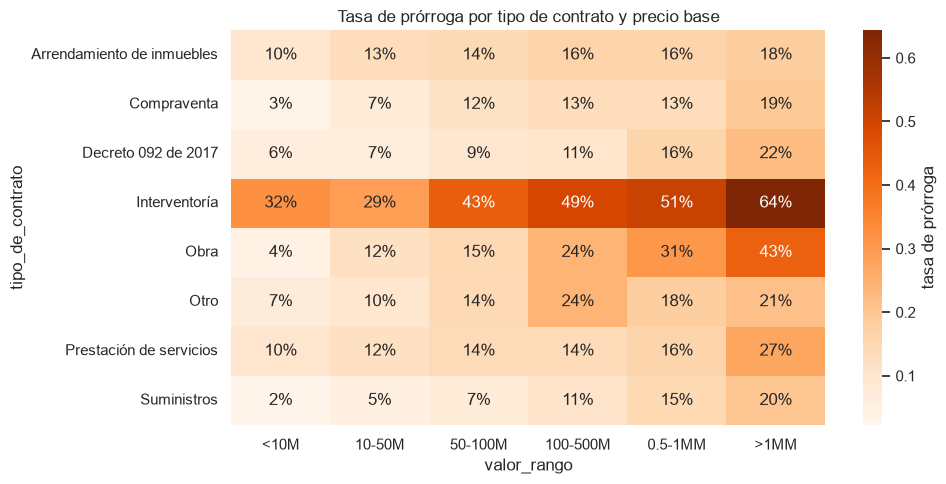

In [10]:
# Mapa de calor tipo de contrato x valor: interacción relevante para el modelo
top_tipos = df["tipo_de_contrato"].value_counts().head(8).index
df["valor_rango"] = pd.cut(df["proc_precio_base"], [0, 1e7, 5e7, 1e8, 5e8, 1e9, np.inf],
                           labels=["<10M", "10-50M", "50-100M", "100-500M", "0.5-1MM", ">1MM"])
piv = (df[df["tipo_de_contrato"].isin(top_tipos)]
       .pivot_table(index="tipo_de_contrato", columns="valor_rango", values="prorrogado", aggfunc="mean", observed=True))
plt.figure(figsize=(10, 5))
sns.heatmap(piv, annot=True, fmt=".0%", cmap="Oranges", cbar_kws={"label": "tasa de prórroga"})
plt.title("Tasa de prórroga por tipo de contrato y precio base")
guardar("05_heatmap_tipo_valor")

## 4. Territorio y entidad

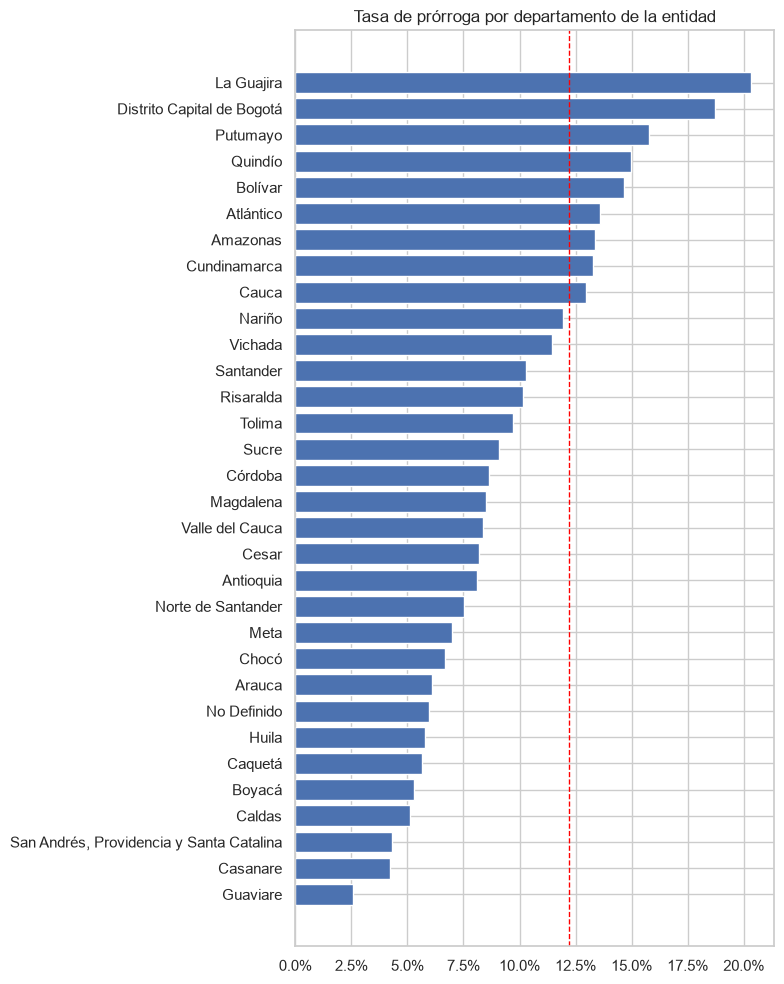

In [11]:
dep = tasa_por("departamento", min_n=1000, top=40).sort_values("tasa")
plt.figure(figsize=(8, 10))
plt.barh(dep.index, dep["tasa"]); plt.axvline(TASA_GLOBAL, color="red", ls="--", lw=1)
plt.gca().xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.title("Tasa de prórroga por departamento de la entidad")
guardar("06_departamento")

1,612 entidades con ≥100 contratos | percentiles de su tasa de prórroga:
0.100   0.000
0.250   0.013
0.500   0.048
0.750   0.125
0.900   0.223
Name: tasa, dtype: float64


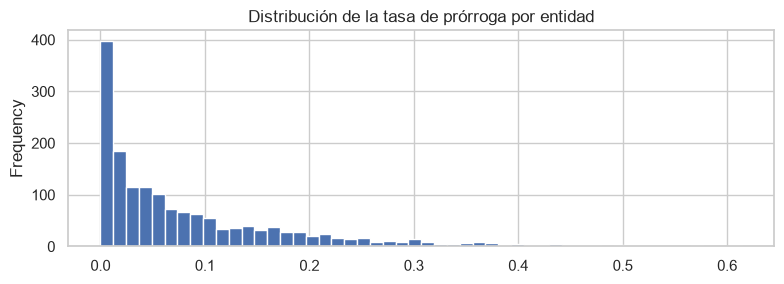

In [12]:
# Heterogeneidad entre entidades: sugiere usar la tasa histórica de la entidad como variable
ent = df.groupby("codigo_entidad")["prorrogado"].agg(n="size", tasa="mean").query("n >= 100")
print(f"{len(ent):,} entidades con ≥100 contratos | percentiles de su tasa de prórroga:")
print(ent["tasa"].quantile([.1, .25, .5, .75, .9]).round(3))
ent["tasa"].plot.hist(bins=50, figsize=(8, 3), title="Distribución de la tasa de prórroga por entidad")
guardar("07_entidades")

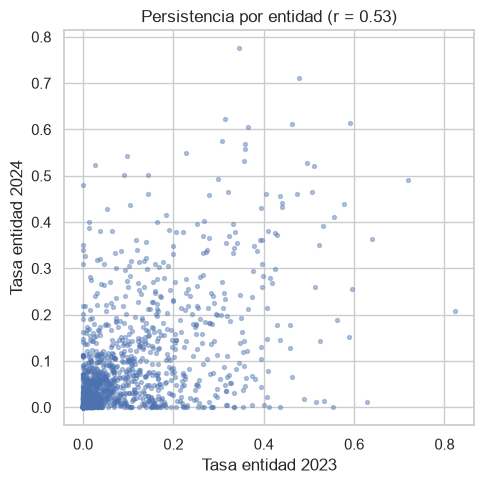

In [13]:
# ¿La tasa de la entidad en 2023 predice la de 2024? (insumo para una variable histórica sin fuga)
e = df.pivot_table(index="codigo_entidad", columns="anio_firma", values="prorrogado", aggfunc=["mean", "size"])
e = e[(e[("size", 2023)] >= 50) & (e[("size", 2024)] >= 50)]
r = e[("mean", 2023)].corr(e[("mean", 2024)])
plt.figure(figsize=(5, 5))
plt.scatter(e[("mean", 2023)], e[("mean", 2024)], s=8, alpha=.4)
plt.xlabel("Tasa entidad 2023"); plt.ylabel("Tasa entidad 2024"); plt.title(f"Persistencia por entidad (r = {r:.2f})")
guardar("08_persistencia_entidad")

## 5. Competencia del proceso y perfil del proveedor (tablas cruzadas)

Contratos con proceso cruzado: 99.6%
Contratos con proveedor cruzado: 98.1%


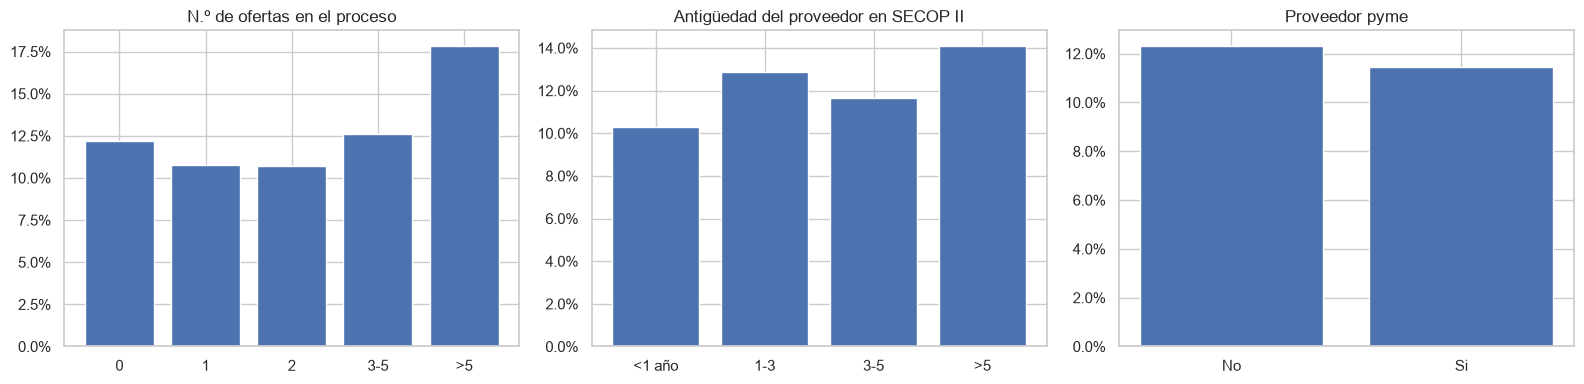

In [14]:
print(f"Contratos con proceso cruzado: {df['proc_id_del_portafolio'].notna().mean():.1%}")
print(f"Contratos con proveedor cruzado: {df['prov_codigo'].notna().mean():.1%}")
df["respuestas_rango"] = pd.cut(df["proc_respuestas_al_procedimiento"], [-1, 0, 1, 2, 5, np.inf], labels=["0", "1", "2", "3-5", ">5"])
df["antig_prov"] = pd.cut(df["prov_antiguedad_dias"] / 365, [-np.inf, 1, 3, 5, np.inf], labels=["<1 año", "1-3", "3-5", ">5"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, t in zip(axes, ["respuestas_rango", "antig_prov", "es_pyme"],
                      ["N.º de ofertas en el proceso", "Antigüedad del proveedor en SECOP II", "Proveedor pyme"]):
    g = df.groupby(col, observed=True)["prorrogado"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"]); ax.set_title(t)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
guardar("09_proceso_proveedor")

## 6. Fuga de información (leakage)

Variables que solo existen **después** de la firma no pueden entrar al modelo. Hallazgo crítico: `valor_del_contrato`
**se actualiza con las adiciones**. Si el valor final supera el precio base del proceso, la tasa de prórroga se dispara.
Por eso el monto que usará el modelo es `proc_precio_base`.

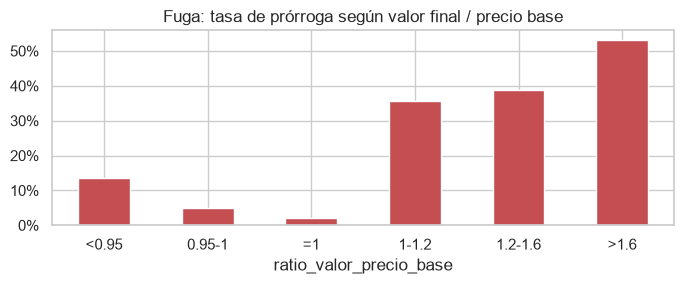

,n,tasa
ratio_valor_precio_base,,
<0.95,207687,0.137
0.95-1,41282,0.049
=1,1045450,0.019
1-1.2,103104,0.357
1.2-1.6,253905,0.387
>1.6,38802,0.532


,spearman,fuga
dias_adicionados,0.997,True
ratio_valor_precio_base,0.325,True
exceso_duracion,0.277,True
duracion_real_dias,0.234,True
log_valor,0.164,True
valor_del_contrato,0.164,True
valor_pendiente_de_ejecucion,0.161,True
duracion_pactada_dias,0.134,False
recursos_propios,0.077,False
log_precio_base,0.076,False


In [15]:
r = pd.cut(df["ratio_valor_precio_base"], [0, .95, .999, 1.001, 1.2, 1.6, np.inf],
           labels=["<0.95", "0.95-1", "=1", "1-1.2", "1.2-1.6", ">1.6"])
g = df.groupby(r, observed=True)["prorrogado"].agg(n="size", tasa="mean")
ax = g["tasa"].plot.bar(figsize=(7, 3), rot=0, color="#C44E52",
                        title="Fuga: tasa de prórroga según valor final / precio base")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
guardar("10_fuga_valor")
display(g)
df["exceso_duracion"] = df["duracion_real_dias"] - df["duracion_pactada_dias"]
num = df.select_dtypes("number").drop(columns=["prorrogado"])
# Spearman = Pearson sobre rangos
corr = num.rank().corrwith(df["prorrogado"]).dropna().sort_values(key=abs, ascending=False)
pd.DataFrame({"spearman": corr.round(3), "fuga": corr.index.isin(FUGA + ["exceso_duracion"])}).head(15)

## 7. Conclusiones

1. **Objetivo viable y desbalanceado:** 12,2% de 1,70 M contratos (2023–2024, ya terminados) fue prorrogado; la mediana
   de la prórroga es de 35 días. Se modelará como clasificación binaria con métricas para desbalance (AUC-PR, recall).
2. **El riesgo depende fuertemente del tipo de contrato:** interventoría 46%, obra 24%, consultoría 22% vs. suministros 7%.
   Por modalidad: licitación de obra pública 44% y concurso de méritos 41% vs. mínima cuantía 8%.
3. **Tamaño y plazo:** la tasa sube con el precio base (9% → 20% entre deciles) y con la duración pactada
   (7% en contratos ≤1 mes vs. 50% en 1–2 años). La interacción tipo × monto es clave: obra >1.000 M COP llega a 43%
   e interventoría >1.000 M COP a 64%.
4. **La entidad importa:** entre entidades con ≥100 contratos la tasa va de 0% (p10) a 22% (p90) y es persistente
   (r = 0,53 entre 2023 y 2024). Se usará la tasa histórica de la entidad (calculada solo con contratos anteriores) como variable.
5. **Competencia y proveedor aportan poco por sí solos** (procesos con >5 ofertas: 18%; antigüedad y pyme: diferencias
   de 1–4 pp), pero los cruces con Procesos (99,6%) y Proveedores (98,1%) son casi completos.
6. **Fuga de información detectada:** `valor_del_contrato` incluye las adiciones (si supera el precio base la tasa pasa de
   2% a 36–53%). El modelo usará `proc_precio_base`; además se excluyen pagos, facturación, estado y fechas reales de fin.
7. **Calidad:** hay valores y duraciones extremos (p. ej. contratos de 6×10¹⁵ COP o duraciones de millones de días) que
   se deben recortar o winsorizar; 91% de procesos sin fecha de adjudicación (contratación directa).

**Implicación para el prototipo:** formulario con tipo de contrato, modalidad, entidad, precio base, duración pactada y
departamento → la API devuelve la probabilidad de prórroga y su comparación con contratos similares.
